# Step 1 — REINFORCE: what a policy network actually is

The goal: train a neural network to play the **two-player duel**, and have it land on
survival probabilities we already know exactly.

Two players, accuracies 0.4 and 0.8. If both always shoot, the exact answer is

$$W(p, q) = \frac{p}{p + q}$$

so the weak player survives $0.4 / 1.2 = 1/3$ and the strong player $2/3$.
**Those two numbers are the target.**

Why a duel and not the three-player game: a duel has one decision and no targeting
problem, so it converges in seconds. That separates "is my gradient update correct"
from "has it trained long enough", which look identical from outside.

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from gruel_env import ACTION_NAMES, GruelEnv, N_ACTIONS

SEED = 0

# Two seeds, kept separate on purpose. One drives the game's luck (who acts, whether a
# shot hits), the other drives the network's weights and action sampling. Keeping them
# apart means "the same policy, different luck" is a thing you can actually test.
GAME_SEED = 1000 + SEED
TORCH_SEED = 2000 + SEED

torch.manual_seed(TORCH_SEED)

# One thread. The default is to use every core, which makes runs non-reproducible
# because floating-point addition depends on the order the threads finish in.
torch.set_num_threads(1)

print("torch", torch.__version__)

torch 2.2.2


## The exact answer, before any training

Work out the target first. A number computed after seeing the measurement is not a
prediction, it is a description.

The derivation, in words: one player is drawn at random each step, so with
probability $1/2$ the weak player acts and hits with probability $p$. If nobody hits,
the game is in exactly the state it started in — so the same unknown $W$ appears on
both sides and can be solved for.

In [2]:
WEAK_ACCURACY = 0.4
STRONG_ACCURACY = 0.8


def duel_survival(own_accuracy, other_accuracy):
    """Probability the first player wins a two-player duel, if both always shoot."""
    return own_accuracy / (own_accuracy + other_accuracy)


exact_weak = duel_survival(WEAK_ACCURACY, STRONG_ACCURACY)
exact_strong = duel_survival(STRONG_ACCURACY, WEAK_ACCURACY)

print("exact survival, weak player  (0.4):", round(exact_weak, 4))
print("exact survival, strong player (0.8):", round(exact_strong, 4))
print("they sum to:", exact_weak + exact_strong)

exact survival, weak player  (0.4): 0.3333
exact survival, strong player (0.8): 0.6667
they sum to: 1.0


## The policy network

Four numbers in (own accuracy, left neighbour's, right neighbour's, fraction of
players still alive), three numbers out (one per action).

The three outputs are **not** probabilities. They are unbounded scores, called
logits. Turning them into probabilities is the next cell's job.

In [3]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class PolicyNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.first_layer = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.activation = nn.Tanh()
        self.second_layer = nn.Linear(HIDDEN_SIZE, N_ACTIONS)

    def forward(self, observation):
        hidden = self.first_layer(observation)
        hidden = self.activation(hidden)
        logits = self.second_layer(hidden)
        return logits


policy = PolicyNetwork()
print(policy)

total_parameters = 0
for parameter in policy.parameters():
    total_parameters = total_parameters + parameter.numel()
print("parameters:", total_parameters)

PolicyNetwork(
  (first_layer): Linear(in_features=4, out_features=64, bias=True)
  (activation): Tanh()
  (second_layer): Linear(in_features=64, out_features=3, bias=True)
)
parameters: 515


## Turning three scores into an action

`Categorical` is the irreducible bit. It does two jobs at once:

1. converts the three logits into probabilities that sum to 1, and samples one,
2. remembers enough about that sample to differentiate through it later.

The second job is why `numpy.random.choice` will not do. Sampling by hand gives a
number; this gives a number that still knows which weights produced it.

In [4]:
example_observation = torch.tensor([0.4, 0.8, 0.8, 1.0])
example_logits = policy(example_observation)
print("logits:       ", example_logits.detach().numpy().round(4))

distribution = torch.distributions.Categorical(logits=example_logits)
print("probabilities:", distribution.probs.detach().numpy().round(4))
print("they sum to:  ", float(distribution.probs.sum()))

sampled_action = distribution.sample()
print("sampled action:", int(sampled_action), ACTION_NAMES[int(sampled_action)])
print("log-probability of that action:", round(float(distribution.log_prob(sampled_action)), 4))

logits:        [-0.002  -0.197  -0.3148]
probabilities: [0.3915 0.3221 0.2863]
they sum to:   1.0
sampled action: 1 shoot_right
log-probability of that action: -1.1328


## A log-probability is never positive

Worth pausing on, because the sign carries the whole update. A probability is at most
1, so its logarithm is at most 0. An action the policy was certain about scores
nearly 0; an action it thought unlikely scores a large negative number.

In [5]:
for probability in [0.999, 0.5, 0.1, 0.001]:
    print("probability", format(probability, ".3f"), "-> log", round(float(torch.log(torch.tensor(probability))), 4))

probability 0.999 -> log -0.001
probability 0.500 -> log -0.6931
probability 0.100 -> log -2.3026
probability 0.001 -> log -6.9078


## Playing one episode, decision by decision

In a duel each player has only one opponent, so `shoot_left` and `shoot_right` hit
the same person. The real choice is **shoot or abstain**.

Printed below is one untrained episode. The policy is random at this point, so
expect abstentions and a long game.

In [6]:
def play_one_episode(game, policy, trace=False):
    """Play a duel to the end. Returns the log-probabilities, who acted, and the winner."""
    game.reset()

    log_probabilities = []
    actors = []

    for acting_agent in game.agent_iter():
        observation, reward, termination, truncation, info = game.last()

        # A finished agent is handed to us one last time, so PettingZoo can retire it.
        # Stepping with None is how we say 'nothing to do here'.
        if termination or truncation:
            game.step(None)
            continue

        actor = game.position_of_agent[acting_agent]
        observation_tensor = torch.from_numpy(observation)

        logits = policy(observation_tensor)
        distribution = torch.distributions.Categorical(logits=logits)
        action = distribution.sample()
        log_probability = distribution.log_prob(action)

        log_probabilities.append(log_probability)
        actors.append(actor)

        if trace:
            chosen = int(action)
            target = game.target_of(acting_agent, chosen)
            if target is None:
                description = "abstains"
            else:
                description = "shoots position " + str(target)
            print(
                "  t=" + str(game.t + 1).rjust(3)
                + "  " + acting_agent
                + " (p=" + format(game.accuracies[actor], ".1f") + ")"
                + "  " + ACTION_NAMES[chosen].ljust(11)
                + "  " + description
            )

        game.step(int(action))

        if trace and game.reason is not None:
            print("  ended:", game.reason, " alive:", game.order)

    if len(game.order) == 1:
        winner = game.order[0]
    else:
        winner = None

    return log_probabilities, actors, winner


game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=GAME_SEED)

# reset() is what deals the accuracies out to positions, so there is nothing to read
# before it has been called once.
game.reset()
print("accuracies by position:", [round(float(a), 2) for a in game.accuracies])
print()
log_probabilities, actors, winner = play_one_episode(game, policy, trace=True)
print()
print("decisions made this episode:", len(log_probabilities))
print("winner position:            ", winner)

accuracies by position: [0.4, 0.8]

  t=  1  player_1 (p=0.8)  miss         abstains
  t=  2  player_1 (p=0.8)  shoot_left   shoots position 0
  ended: sole_survivor  alive: [1]

decisions made this episode: 2
winner position:             1


## The REINFORCE update

For each decision, the loss is

$$-\log \pi(a \mid s) \times R$$

where $R$ is the reward that decision's *owner* got at the end of the episode.
Minimising this maximises reward: if $R$ is positive, minimising $-\log \pi$ pushes
$\log \pi$ up, which pushes the probability of that action up.

Note what $R$ is here — **one number for the whole episode**. Every decision that
player made gets the same credit. A correct move in a lost episode gets none of it.
That is REINFORCE's central weakness, and step 2 is the fix.

In [7]:
def episode_loss(log_probabilities, actors, winner):
    """The REINFORCE loss for one episode."""
    losses = []
    for index in range(len(log_probabilities)):
        log_probability = log_probabilities[index]
        actor = actors[index]

        if actor == winner:
            reward = 1.0
        else:
            reward = 0.0

        loss_for_this_decision = -log_probability * reward
        losses.append(loss_for_this_decision)

    stacked = torch.stack(losses)
    return stacked.mean()


loss = episode_loss(log_probabilities, actors, winner)
print("loss for that episode:", round(float(loss), 4))

loss for that episode: 1.1163


## Where the gradient comes from, and where it does not

Under the `terminal` reward $R$ is 1 for the winner and 0 for everybody else. So
every decision made by the player who lost is multiplied by zero and contributes
**nothing at all**. Only the winner's actions are pushed up.

That is worth seeing rather than being told, because it is the reason the training
curve below wobbles: roughly half of every batch is discarded by the arithmetic.

In [8]:
contributing = 0
silent = 0
untrained_game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=GAME_SEED)

for _ in range(200):
    _, episode_actors, episode_winner = play_one_episode(untrained_game, policy)
    for actor in episode_actors:
        if actor == episode_winner:
            contributing = contributing + 1
        else:
            silent = silent + 1

total_decisions = contributing + silent
print("over 200 episodes with the untrained policy:")
print("  decisions that produced gradient:", contributing)
print("  decisions multiplied by zero:    ", silent)
print("  share discarded:                 ", format(silent / total_decisions, ".3f"))
print()
print("smallest possible value of this loss:", 0.0, "- because log pi <= 0 and R >= 0")

over 200 episodes with the untrained policy:
  decisions that produced gradient: 322
  decisions multiplied by zero:     125
  share discarded:                  0.280

smallest possible value of this loss: 0.0 - because log pi <= 0 and R >= 0


## Training

One episode at a time is too noisy, so average the loss over a small batch of
episodes before each update.

`loss.backward()` is the other irreducible line. It walks the whole computation
backwards and fills in the gradient for every weight.

In [9]:
def train(policy, episodes=6000, batch_size=32, learning_rate=0.01, game_seed=GAME_SEED):
    game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=game_seed)
    optimiser = torch.optim.Adam(policy.parameters(), lr=learning_rate)

    history_episode = []
    history_weak_survival = []

    batch_losses = []
    recent_winners = []

    for episode_number in range(episodes):
        log_probabilities, actors, winner = play_one_episode(game, policy)

        if len(log_probabilities) > 0:
            batch_losses.append(episode_loss(log_probabilities, actors, winner))

        if winner is None:
            recent_winners.append(None)
        else:
            recent_winners.append(float(game.accuracies[winner]))

        # Update once per batch.
        if len(batch_losses) >= batch_size:
            total_loss = torch.stack(batch_losses).mean()

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

            batch_losses = []

        # Record how often the weak player survives, over the last 500 episodes.
        if (episode_number + 1) % 500 == 0:
            weak_wins = 0
            for accuracy in recent_winners[-500:]:
                if accuracy == WEAK_ACCURACY:
                    weak_wins = weak_wins + 1
            history_episode.append(episode_number + 1)
            history_weak_survival.append(weak_wins / 500)

    return history_episode, history_weak_survival

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [10]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step1_reinforce.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [11]:
def reinforce_settings(episodes, torch_seed, game_seed, seconds):
    return {
        "algorithm": "REINFORCE, one shared policy, no critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": "none",
        "game": {"n_players": 2, "reward": "terminal", "seating": "ranked", "accuracies_ascending": accuracies_ascending(2), "stagnation_rounds": 10},
        "training": {"episodes": episodes, "batch_size": 32, "optimiser": "Adam",
                     "learning_rate": 0.01, "discount": 1.0,
                     "loss": "minus log-probability times the episode reward, averaged over a batch"},
        "seeds": {"torch": torch_seed, "training_game": game_seed},
        "seconds": round(seconds, 1),
        "seconds_cover": "training only",
    }


torch.manual_seed(TORCH_SEED)
policy = PolicyNetwork()
started = time.time()
episodes_axis, weak_survival = train(policy)
save_model(policy, "n2_ranked_terminal_reinforce_e6000_seed%d" % SEED,
           reinforce_settings(6000, TORCH_SEED, GAME_SEED, time.time() - started))

print("target for the weak player:", round(exact_weak, 4))
print("last five measurements:    ", [round(v, 4) for v in weak_survival[-5:]])

target for the weak player: 0.3333
last five measurements:     [0.346, 0.344, 0.31, 0.348, 0.316]


## Did it learn?

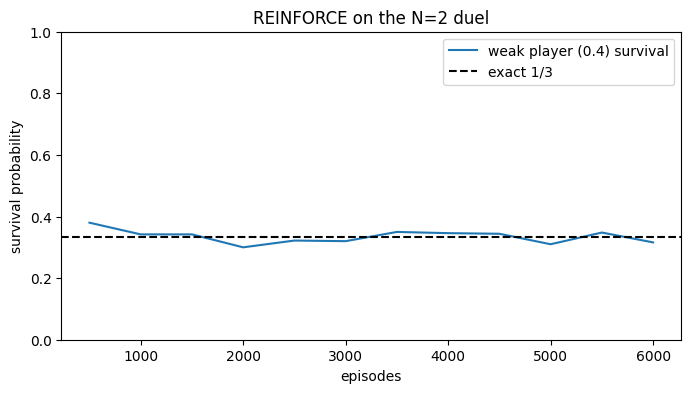

In [12]:
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(episodes_axis, weak_survival, label="weak player (0.4) survival")
axis.axhline(exact_weak, linestyle="--", color="black", label="exact 1/3")
axis.set_xlabel("episodes")
axis.set_ylabel("survival probability")
axis.set_title("REINFORCE on the N=2 duel")
axis.set_ylim(0, 1)
axis.legend()
plt.show()

## What the trained policy actually does

The number to watch is how often it abstains. Abstaining in a duel is suicide — you
give the other player free shots — so a working policy should learn to almost never
do it.

`shoot_left` and `shoot_right` point at the same opponent here, so how the policy
splits its weight between those two is arbitrary. Only their **total** matters.

In [13]:
observation_weak = torch.tensor([0.4, 0.8, 0.8, 1.0])
observation_strong = torch.tensor([0.8, 0.4, 0.4, 1.0])

for name, observation in [("weak (0.4)", observation_weak), ("strong (0.8)", observation_strong)]:
    logits = policy(observation)
    probabilities = torch.distributions.Categorical(logits=logits).probs
    values = probabilities.detach().numpy()
    shoots = values[0] + values[1]
    print(
        "  " + name.ljust(14)
        + " shoot_left " + format(values[0], ".4f")
        + "  shoot_right " + format(values[1], ".4f")
        + "  miss " + format(values[2], ".4f")
        + "   -> shoots " + format(shoots, ".4f")
    )

  weak (0.4)     shoot_left 0.4767  shoot_right 0.5226  miss 0.0007   -> shoots 0.9993
  strong (0.8)   shoot_left 0.4857  shoot_right 0.5137  miss 0.0005   -> shoots 0.9995


## Measuring the trained policy properly

Training numbers are noisy because the policy is changing as they are collected. So
evaluate separately: freeze the policy and play a lot of episodes.

`torch.no_grad()` says "no training here", which makes it faster.

In [14]:
def evaluate(policy, episodes=20000, game_seed=5000):
    game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=game_seed)
    survivals = {WEAK_ACCURACY: 0, STRONG_ACCURACY: 0}
    completed = 0

    with torch.no_grad():
        for _ in range(episodes):
            game.reset()
            for acting_agent in game.agent_iter():
                observation, reward, termination, truncation, info = game.last()

                # A finished agent is handed to us one last time, so PettingZoo can
                # retire it. Stepping with None is how we say 'nothing to do here'.
                if termination or truncation:
                    game.step(None)
                    continue

                observation_tensor = torch.from_numpy(observation)
                logits = policy(observation_tensor)
                distribution = torch.distributions.Categorical(logits=logits)
                action = int(distribution.sample())
                game.step(action)

            if len(game.order) == 1:
                winning_accuracy = float(game.accuracies[game.order[0]])
                survivals[winning_accuracy] = survivals[winning_accuracy] + 1
                completed = completed + 1

    return survivals, completed


EVALUATION_EPISODES = 20000
survivals, completed = evaluate(policy, episodes=EVALUATION_EPISODES)
print("completed episodes:", completed, "of", EVALUATION_EPISODES)
print()

exact = {WEAK_ACCURACY: exact_weak, STRONG_ACCURACY: exact_strong}
for accuracy in [WEAK_ACCURACY, STRONG_ACCURACY]:
    measured = survivals[accuracy] / EVALUATION_EPISODES
    target = exact[accuracy]
    print(
        "  acc " + str(accuracy)
        + ": measured " + format(measured, ".4f")
        + "   exact " + format(target, ".4f")
        + "   ratio " + format(measured / target, ".3f")
    )

completed episodes: 20000 of 20000

  acc 0.4: measured 0.3301   exact 0.3333   ratio 0.990
  acc 0.8: measured 0.6700   exact 0.6667   ratio 1.005


## Reproducibility

Same seeds, twice, from scratch. The two runs must be identical — not close,
identical. If they are not, something is drawing on hidden global random state.

In [15]:
def train_from_scratch():
    torch.manual_seed(TORCH_SEED)
    fresh_policy = PolicyNetwork()
    _, weak_history = train(fresh_policy, episodes=2000)
    return weak_history


first_run = train_from_scratch()
second_run = train_from_scratch()

print("run 1:", [round(v, 4) for v in first_run])
print("run 2:", [round(v, 4) for v in second_run])
print()
print("identical:", first_run == second_run)

run 1: [0.38, 0.342, 0.342, 0.3]
run 2: [0.38, 0.342, 0.342, 0.3]

identical: True
